# Dataset Description
## Taxes

**Source**: [DIAN](https://www.dian.gov.co/dian/cifras/Paginas/EstadisticasRecaudo.aspx)

# Code
## Imports

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

## Load data

In [53]:
path = "./data/Recaudo-anual-por-tipo-de-impuesto-1970-2026.csv"

df = pd.read_csv(
    path, encoding="utf-8", usecols=[0,2,3],
    header=0,
    names=["year", "income_tax", "withholding"]
)

## Clean data

In [54]:
df = df[~(df["year"].str.contains("(p)", regex=False))]
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 1990]
df["greater"] = df["income_tax"] / df["withholding"]

## Plot

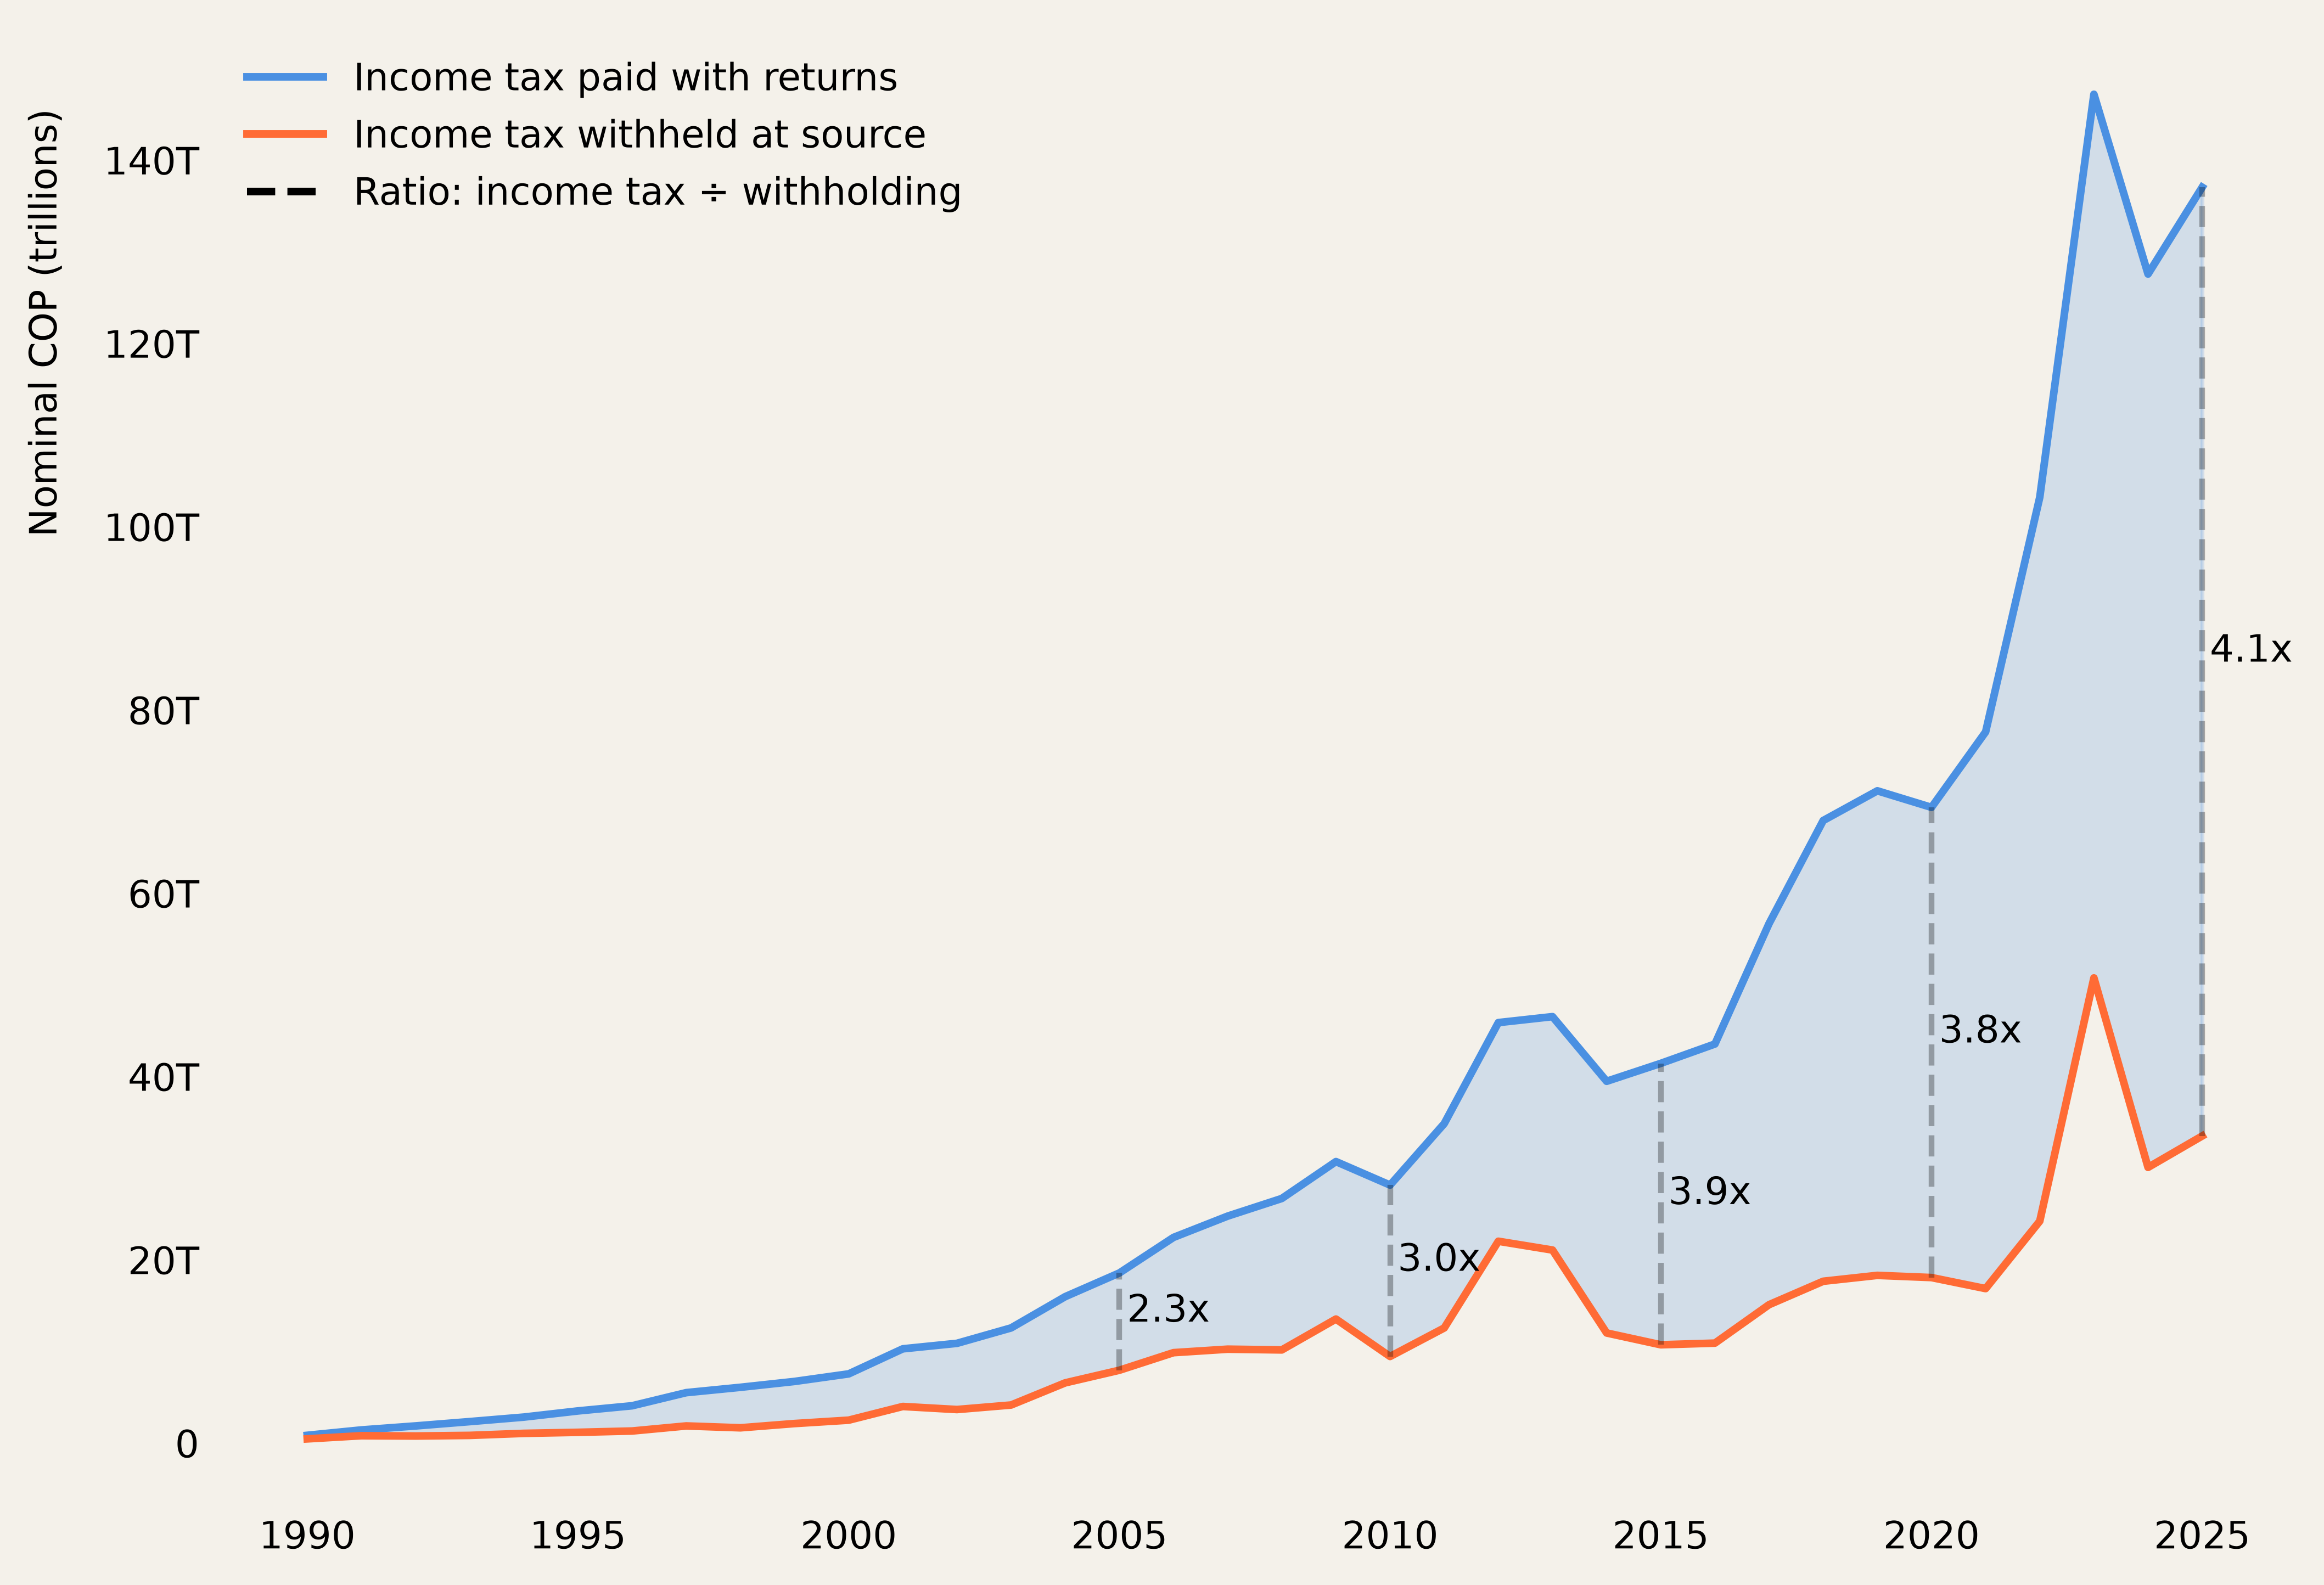

In [65]:
background = "#F4F1EA"

colors = ["#4a90e2", "#FF6B35"]

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

for i, column in enumerate(df.columns[1:-1]):
    plt.plot(
        df["year"], df[column],
        linewidth=2, color=colors[i]
    )

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{int(x/1000000)}T" if x != 0 else "0"
    )
)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.fill_between(
    df["year"], df["income_tax"], df["withholding"],
    where=df["income_tax"] >= df["withholding"], color=colors[0], alpha=0.2
)

plt.ylabel("Nominal COP (trillions)", labelpad=10, fontsize=10, y=0.8)

for year in range(2005, 2030, 5):
    buffer = df[df["year"].eq(year)]
    value = buffer["greater"].iloc[0]
    income_tax = buffer["income_tax"].iloc[0]
    withholding = buffer["withholding"].iloc[0]
    y = (income_tax + withholding) / 2 
    
    plt.annotate(
        f"{value:.1f}x",
        xy=(year,y),
        xytext=(2,0),
        textcoords="offset points"
    )

    plt.vlines(
        x=year,
        ymin=withholding,
        ymax=income_tax,
        colors="black",
        linestyles="--",
        alpha=0.3
    )

handles = [
    Line2D([0], [0], color=colors[0], lw=2, label="Income tax paid with returns"),
    Line2D([0], [0], color=colors[1], lw=2, label="Income tax withheld at source"),
    Line2D([0], [0], color="black", lw=2, linestyle="--" ,label="Ratio: income tax ÷ withholding"),
]

ax.legend(handles=handles)

plt.legend(
    handles=handles,
    frameon=False
)

plt.show()